# Eco-Concrete Strength Modeling (Notebook 1)

**Dataset:** UCI Concrete Compressive Strength

**Goal:** Rationalize the dataset to build a baseline concrete strength model for **compressive strength (MPa)** from concrete mixture compositions and **sustainability** (estimated CO₂ + cost proxies) to visualize tradeoffs.

> This notebook is designed to be a clean starting point for modeling.  
> It runs end-to-end once the dataset CSV is available locally.

---
## In this notebook:
1. Load + validate the dataset
2. Quick EDA + sanity checks
3. Train/test split with reproducible evaluation
4. Models:
    - Linear Regression (baseline)
    - Random Forest (nonlinear)
    - Gradient Boosting (strong general baseline)
5. Model evaluation metrics: **R²** and **MAE**
6. Simple **tradeoff plots**: predicted strength vs estimated CO₂ and “cost proxy”

---
## 0) Setup: establishing the dataset

The current dataset is from UCI Machine Learning Repository; however, versions of this dataset are available on Kaggle.

Kaggle datasets usually require either:
1) **Manual download** of the CSV from Kaggle (https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength), or  
2) Kaggle API (`kaggle datasets download ...`) after setting up an API token.

**Recommended for simplicity:**  
Download the dataset zip and extract the CSV into:
```
./data/
```
This notebook will look for a CSV file in `./data/` automatically.



In [1]:
# Installs dependencies when running in Google Colab.
# If these packages are already installed, this cell will finish quickly.
!pip -q install scikit-learn pandas numpy matplotlib

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Machine learning tools
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, make_scorer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

# Ensures repeatability
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Output prefix keeps baseline results separate from future RCA results
OUTPUT_PREFIX = "baseline"

# Default output folders. These are replaced by the data-loading cell when Drive/repo paths are set.
FIG_DIR = Path("figures")
OUT_DIR = Path("outputs")
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Setup complete.")


Setup complete.


## 1) Load the dataset

The UCI Concrete Compressive Strength dataset typically contains one main CSV with columns like:
- Supplementary Cementitious Materials (SCMs)
  - **Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer**
- Aggregates
  - **Coarse Aggregate, Fine Aggregate**, (varies based on material and source)
- Other Variables
  - **Age**, Temperature, Environmental/Chemical Exposure
- Target Values
  - **Compressive Strength (MPa)**, Tensile Strength, Elasticity Modulus

We’ll auto-detect the CSV in `./data/`. If you have multiple CSVs, we’ll pick the one that looks like the concrete dataset. All the bolded variables are included in the CSV already loaded in the notebook.

For local or drive options, you may add your dataset here:
```
./data/Concrete_Data.csv
```


In [18]:
from pathlib import Path
import numpy as np
import pandas as pd

# ============================================================
# Project configuration
# ============================================================
# Keep RUN_MODE as "drive" for now because the project is still running through Google Drive.
# Later, switch RUN_MODE to "repo" when running from the GitHub repository.
RUN_MODE = "drive"       # options: "drive", "repo", or "auto"
DATASET_VERSION = "baseline"   # future option: "rca"
OUTPUT_PREFIX = DATASET_VERSION

DATASET_FILES = {
    "baseline": "concrete_data.csv",
    "rca": "rca_concrete_data.csv",  # placeholder for future recycled aggregate dataset
}

expected_csv = DATASET_FILES[DATASET_VERSION]
base_candidates = []

# Try the Google Drive project folder first when requested.
if RUN_MODE in ["drive", "auto"]:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        base_candidates.append(Path("/content/drive/MyDrive/Indigo Research Project"))
        print("Google Drive is mounted.")
    except Exception as e:
        print("Google Drive mount not available in this environment. Falling back to local/repo paths.")
        print("Drive message:", e)

# Local/repo fallbacks. These make the notebook runnable from GitHub later.
if RUN_MODE in ["repo", "auto", "drive"]:
    cwd = Path.cwd()
    base_candidates.extend([
        cwd.parent if cwd.name == "notebooks" else cwd,  # repo root if running inside notebooks/
        cwd,
        Path("/mnt/data"),  # useful for local testing only
    ])

# Remove duplicate candidates while preserving order.
seen = set()
unique_base_candidates = []
for candidate in base_candidates:
    resolved = str(candidate)
    if resolved not in seen:
        unique_base_candidates.append(candidate)
        seen.add(resolved)

csv_path = None
BASE_DIR = None
DATA_DIR = None

for base in unique_base_candidates:
    possible_data_dirs = [base / "data", base]
    for data_dir in possible_data_dirs:
        candidate = data_dir / expected_csv
        if candidate.exists():
            csv_path = candidate
            BASE_DIR = base
            DATA_DIR = data_dir
            break
    if csv_path is not None:
        break

# If the real dataset is not found, create a small DEMO dataset so the notebook can still run.
# Do not use demo-data results in the paper. Upload concrete_data.csv to use real results.
if csv_path is None:
    print("WARNING: Could not find the real dataset file:", expected_csv)
    print("Searched these base folders:")
    for base in unique_base_candidates:
        print(" -", base)
    print("\nCreating a synthetic DEMO dataset so the notebook runs without crashing.")
    print("Do not use synthetic demo results for the paper or README.")

    BASE_DIR = unique_base_candidates[0] if unique_base_candidates else Path.cwd()
    DATA_DIR = BASE_DIR / "data"
    rng = np.random.default_rng(RANDOM_STATE)
    n = 300
    df = pd.DataFrame({
        "cement": rng.uniform(100, 550, n),
        "blast_furnace_slag": rng.uniform(0, 250, n),
        "fly_ash": rng.uniform(0, 200, n),
        "water": rng.uniform(120, 240, n),
        "superplasticizer": rng.uniform(0, 25, n),
        "coarse_aggregate": rng.uniform(800, 1200, n),
        "fine_aggregate": rng.uniform(600, 1000, n),
        "age": rng.choice([3, 7, 14, 28, 56, 90, 180, 365], n),
    })
    noise = rng.normal(0, 5, n)
    df["concrete_compressive_strength_mpa"] = (
        0.08 * df["cement"]
        + 0.035 * df["blast_furnace_slag"]
        + 0.020 * df["fly_ash"]
        - 0.11 * df["water"]
        + 0.30 * df["superplasticizer"]
        + 0.025 * np.sqrt(df["age"] * 365)
        + noise
    ).clip(lower=5)
else:
    df = pd.read_csv(csv_path)

# Clean column-name spacing immediately.
df.columns = df.columns.str.strip()

# Output folders.
FIG_DIR = BASE_DIR / "figures"
OUT_DIR = BASE_DIR / "outputs"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("BASE_DIR:", BASE_DIR)
print("DATA_DIR:", DATA_DIR)
print("FIG_DIR:", FIG_DIR)
print("OUT_DIR:", OUT_DIR)
print("Loaded dataset:", csv_path if csv_path is not None else "synthetic DEMO dataset")
print("Dataset version:", DATASET_VERSION)
print("Shape:", df.shape)

df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive is mounted.
BASE_DIR: /content/drive/MyDrive/Indigo Research Project
DATA_DIR: /content/drive/MyDrive/Indigo Research Project/data
FIG_DIR: /content/drive/MyDrive/Indigo Research Project/figures
OUT_DIR: /content/drive/MyDrive/Indigo Research Project/outputs
Loaded dataset: /content/drive/MyDrive/Indigo Research Project/data/concrete_data.csv
Dataset version: baseline
Shape: (1030, 9)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 2) Clean column names + identify target

Different versions of the dataset sometimes have slightly different column names.
We’ll normalize names (lowercase, underscores) and try to auto-detect the target column.

If auto-detection fails, set `TARGET_COL` manually.


In [3]:
# Normalizes the dataset to improve model speed and accuracy
def normalize_col(c: str) -> str:
    c = c.strip().lower()
    c = c.replace(" ", "_")
    c = c.replace("-", "_")
    c = c.replace("(", "").replace(")", "")
    c = c.replace("__", "_")
    return c

df = df.copy()
df.columns = [normalize_col(c) for c in df.columns]

# Notebook specifically analyzes compressive strength
# The following code searches the CSV for this target column
possible_targets = [c for c in df.columns if "strength" in c or "compressive" in c]
print("Possible target columns:", possible_targets)

TARGET_COL = None
for c in possible_targets:
    # Prefer something that explicitly indicates MPa if present
    if "mpa" in c:
        TARGET_COL = c
        break
if TARGET_COL is None and len(possible_targets) == 1:
    TARGET_COL = possible_targets[0]

if TARGET_COL is None:
    # Fallback: common name used in this dataset
    if "concrete_compressive_strength" in df.columns:
        TARGET_COL = "concrete_compressive_strength"
    else:
        raise ValueError(
            "Could not auto-detect target column.\n"
            "Please set TARGET_COL manually after inspecting df.columns."
        )

print("Using TARGET_COL =", TARGET_COL)

# Basic missing-value check
missing = df.isna().sum().sort_values(ascending=False)
print("\nTop missing-value columns:")
print(missing.head(10))

df.describe(include='all').T.head(20)


Possible target columns: ['concrete_compressive_strength']
Using TARGET_COL = concrete_compressive_strength

Top missing-value columns:
cement                           0
blast_furnace_slag               0
fly_ash                          0
water                            0
superplasticizer                 0
coarse_aggregate                 0
fine_aggregate                   0
age                              0
concrete_compressive_strength    0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
blast_furnace_slag,1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
fly_ash,1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
water,1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
superplasticizer,1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
coarse_aggregate,1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
fine_aggregate,1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
age,1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
concrete_compressive_strength,1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


## 3) Quick EDA (sanity checks)

Goals:
- Confirm numeric columns
- Check target distribution
- Look for obvious outliers


Numeric columns: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age', 'concrete_compressive_strength']
Non-numeric columns: []


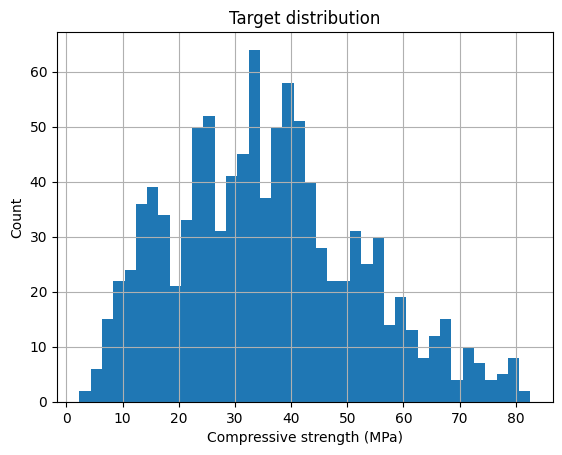

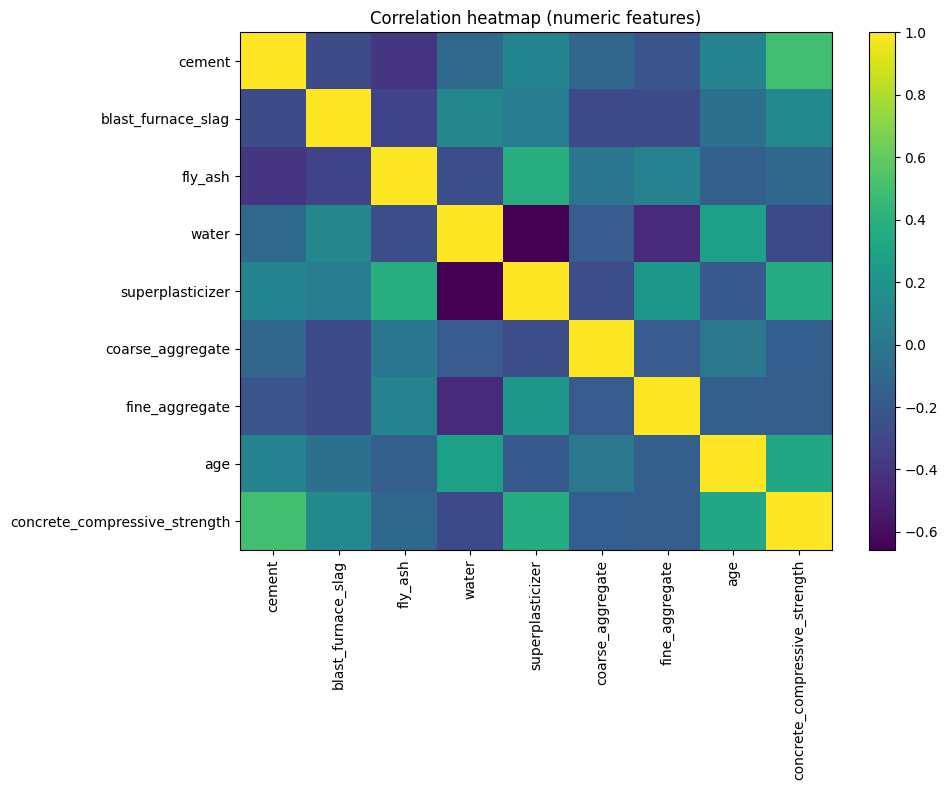

In [4]:
# Ensure numeric columns exist
# Prevents models from crashing during training
for c in df.columns:
    if c == TARGET_COL:
        continue
    # If a column is object but should be numeric, try coercion
    if df[c].dtype == "object":
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Drop rows where target is missing
df = df.dropna(subset=[TARGET_COL]).reset_index(drop=True)

numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
print("Numeric columns:", numeric_cols)
print("Non-numeric columns:", [c for c in df.columns if c not in numeric_cols])

# Target distribution graph
    # Histogram graph shows how MPa varies and shows the mean/median
    # Can be used to improve clustering around a specific MPa
plt.figure()
df[TARGET_COL].hist(bins=40)
plt.xlabel("Compressive strength (MPa)")
plt.ylabel("Count")
plt.title("Target distribution")
plt.show()

# Correlations heatmap (quick glance)
    # Correlation heatmap represents the relationship between materials
    # Yellow is positive correlation (increases together)
    # Purple is negative correlation (decreases together)
    # Graphical representation of feature improtance
corr = df[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation heatmap (numeric features)")
plt.tight_layout()
plt.show()

**Target Distribution Histogram:**
The target distribution graph shows a few peaks around 20-40 MPa, but generally follows a normal distribution (bell-shaped curve).

**Correlation Heatmap:**
The heatmap demonstrates early on that age, cement, and superplasticizer have a positive correlation with concrete compressive strength. Other features seem to have less importance or a negative correlation. It's also clear there are different relationships between features, which is reasonable.

## 4) Train/test split

We’ll define features **X** and target **y**.


In [5]:
# Features = all numeric columns except the target
feature_cols = [c for c in numeric_cols if c != TARGET_COL]
X = df[feature_cols].copy()
y = df[TARGET_COL].copy()

# Train/test split
    # Indicates 20% is for out of box testing and not machine learning
    # random_state variable ensures repeatability
    # This is done to later confirm model performance for new, unseen datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Prints results for viewing
print("Features:", feature_cols)
print("Train:", X_train.shape, "Test:", X_test.shape)


Features: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']
Train: (824, 8) Test: (206, 8)


## 5) Train baseline + stronger models

### Models
- **Linear Regression** (baseline; interpretable)
- **Random Forest** (handles nonlinear interactions well)
- **Gradient Boosting** (often a strong default for tabular regression)

We’ll evaluate with:
- **R²** (higher is better)
- **MAE** in MPa (lower is better)


In [6]:
# Trains and evaluates machine learning models based on R^2 and MAE
def evaluate(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    return {"model": name, "r2": r2, "mae": mae, "fitted_model": model, "y_pred": pred}

models = []

# Linear Regression with standardization (baseline)
lin = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])
# Stores as a model
models.append(("LinearRegression", lin))

# Creates Random Forest Regression
rf = RandomForestRegressor(
# Number of trees, improves quality of model prediction
# Diminishing returns past 200 trees
    n_estimators=400,
# Ensures repeatability
    random_state=42,
# Determines memory consumption and training speed
# "-1" -> utilizes all CPU cores available
    n_jobs=-1,
# Minimum number of samples in final prediction of each tree
# Prevents overfitting
    min_samples_leaf=1
)
# Stores as a model
models.append(("RandomForest", rf))
# Creates Gradient Boosting Regression
gbr = GradientBoostingRegressor(
# Ensures repeatability
    random_state=42
)
# Stores as a model
models.append(("GradientBoosting", gbr))

results = []
fitted = {}

# Displays a ranked comparison of each model and their values
# Higher "r2" value indicates how well the model fits actual data
for name, m in models:
    out = evaluate(name, m, X_train, y_train, X_test, y_test)
    results.append({k: out[k] for k in ["model", "r2", "mae"]})
    fitted[name] = out

results_df = pd.DataFrame(results).sort_values(by="r2", ascending=False)
results_df


,model,r2,mae
2,GradientBoosting,0.882889,4.135014
1,RandomForest,0.881778,3.787604
0,LinearRegression,0.627553,7.745559


## 6) Visualize predictions

We’ll plot predicted vs actual for the best-performing model (by R²).


Best model: GradientBoosting
R²: 0.8828886141958622
MAE: 4.135014150874571 MPa


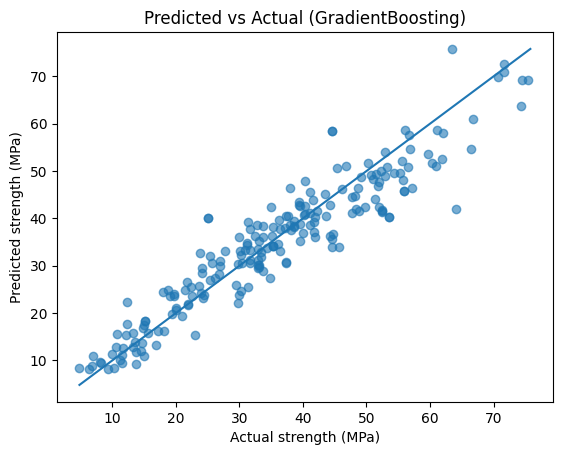

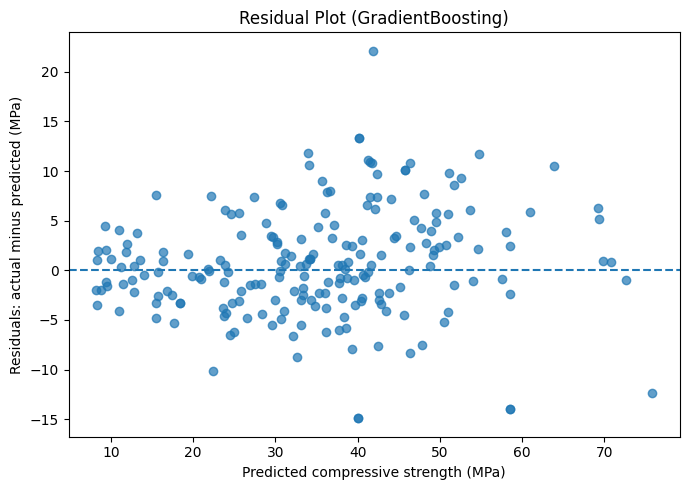

Saved residual plot to: /content/drive/MyDrive/Indigo Research Project/figures/residual_plot_baseline.png


In [7]:
import matplotlib.pyplot as plt

# Defines best model and pulls its results
best_name = results_df.iloc[0]["model"]
best = fitted[best_name]
y_pred = best["y_pred"]

# Prints results
print("Best model:", best_name)
print("R²:", best["r2"])
print("MAE:", best["mae"], "MPa")

# Plots and labels x and y-axis
plt.figure()
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title(f"Predicted vs Actual ({best_name})")
# Places 45-degree line
# Provides a visual aid to determine model accuracy
mn = min(y_test.min(), y_pred.min())
mx = max(y_test.max(), y_pred.max())
plt.plot([mn, mx], [mn, mx])
plt.show()

# Residuals (Negative = Overpredicted, Positive = Underpredicted)
# Provides another way to graph model accuracy
residuals = y_test - y_pred

# Creates and shows histogram of residuals
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted compressive strength (MPa)")
plt.ylabel("Residuals: actual minus predicted (MPa)")
plt.title(f"Residual Plot ({best_name})")
plt.tight_layout()

# Saves figure for publication
residual_fig_path = FIG_DIR / f"residual_plot_{OUTPUT_PREFIX}.png"
plt.savefig(residual_fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved residual plot to:", residual_fig_path)


**Predicted vs Actual Scatterplot:** While inaccurate predictions and outliers exist, the Gradient Boosting model seems to cluster around the plotted line, indicating reasonable model prediction accuracy.

**Residual Distribution Histogram:** Model accuracy is shown to be accurate, with most predicted values hovering within 5 MPa of the actual value. The model seems underpredicts at a lesser magnitude more frequently; however, it also overpredicts more often at a higher magnitude greater than 5 MPa of the actual value.

## 7) Feature importance (permutation importance)

Permutation importance answers if shuffling a feature will degrade a model's performance. This is a good, model-agnostic way to interpret the trained model.


In [8]:
# Defines the best model
best_model = best["fitted_model"]

# Measures importance of each variable using "r2" as a scoring metric
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=20,
    random_state=42,
    scoring="r2"
)

# Sorts variables and provides mean + STD for each
importances = pd.DataFrame({
    "feature": feature_cols,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

# Displays 15 most relevant variables
# Note that in the UCI Concrete Compressive Strength dataset, only 8 variables exist
importances.head(15)


,feature,importance_mean,importance_std
7,age,0.798450,0.042507
0,cement,0.436112,0.040973
3,water,0.227918,0.017233
1,blast_furnace_slag,0.143060,0.017756
4,superplasticizer,0.054934,0.006697
6,fine_aggregate,0.039867,0.007553
5,coarse_aggregate,0.014180,0.003916
2,fly_ash,0.000772,0.002573


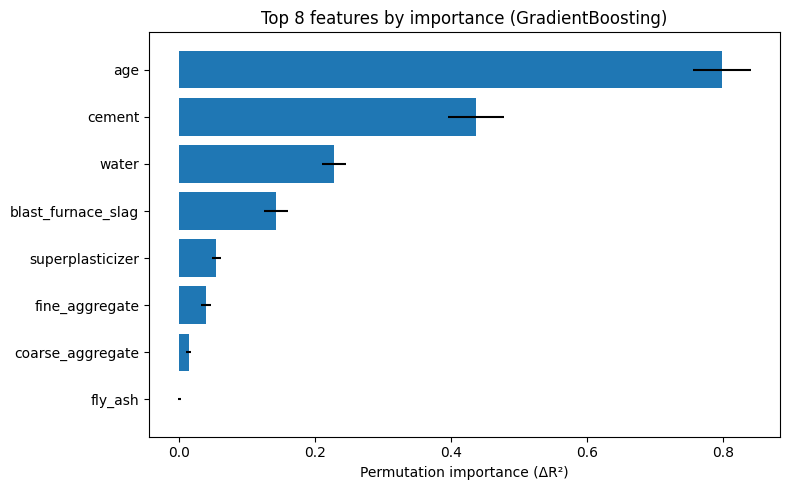

In [9]:
# Number of variables considered
top_k = min(12, len(feature_cols))
# Takes variables and reverses the horizontal bar order for plotting
top = importances.head(top_k).iloc[::-1]

# Plots results of previous code
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Permutation importance (ΔR²)")
plt.title(f"Top {top_k} features by importance ({best_name})")
plt.tight_layout()
plt.show()


**Feature Importance Bar Graph:** Age, cement, and water seem to be the most important features when considering concrete compressive strength, as in they have the greatest effect. This graph matches real-world observations, but does not show the relationship between the feature and the compressive strength of a mixture. Thus, graphs such as the correlation heatmap can be used alongside feature importance to better understand these variables.

## 8) Sustainability layer (CO₂ + cost proxies)

**Important:** The current dataset does *not* include CO₂ emissions or cost.  
To determine sustainability, we create *proxies* from mixture composition.

### How to use this section responsibly
- Treat these as **scenario estimates**, not ground-truth lifecycle assessments.
- Use **literature/CSI** sources to justify the factors you pick.
- Label all plots as proxy analysis unless all values are supported by literature/CSI sources

### Simple proxy approach
Estimate emissions as:
- `CO2_kg = sum_i (mass_i_kg_per_m3 * factor_i_kgCO2_per_kg)`
- `USD_kg = sum_i (mass_i_kg_per_m3 * factor_i_kgUSD_per_kg)`

The current values are defined by literature results and market value estimations as of June 2026.


In [10]:
# Note
    # Current values should be defined or replaced by relevant literature results
    # Current calculations uses GGBFS and natural aggregate data
# CO2 measured in kg CO₂e per kg of material
# Formula determined by material amount in kg/m³ multiplied by factor in kg CO₂e/kg
CO2_FACTORS = {
    "cement": 2614.5,
    "blast_furnace_slag": 393.6586,
    "fly_ash": 314.65,
    "water": 0.196,
    "superplasticizer": 300,
    "coarse_aggregate": 19.05,
    "fine_aggregate": 6.76,
}

# Cost measured in USD per kg of material
# Formula determined by material amount in kg/m³ multiplied by factor in USD/kg
COST_FACTORS = {
    "cement": 226.80,
    "blast_furnace_slag": 148.65,
    "fly_ash": 273.42,
    "water": 9.60,
    "superplasticizer": 963.84,
    "coarse_aggregate": 24.38,
    "fine_aggregate": 20.80,
}

# Map dataset feature names to  factor keys.
# Adjust these if your dataset uses different names.
FEATURE_MAP = {
    "cement": "cement",
    "blast_furnace_slag": "blast_furnace_slag",
    "fly_ash": "fly_ash",
    "water": "water",
    "superplasticizer": "superplasticizer",
    "coarse_aggregate": "coarse_aggregate",
    "fine_aggregate": "fine_aggregate",
    # "age" intentionally excluded from CO2/cost
}

# Check which mapped features exist
missing_features = [f for f in FEATURE_MAP if f not in df.columns]
if missing_features:
    print("WARNING: These expected features are missing from the dataset columns:")
    print(missing_features)
    print("Update FEATURE_MAP to match df.columns.")
else:
    print("All key mixture features found.")


All key mixture features found.


In [11]:
# Inserts factors from previous code and calculates the weighted sum of each row
# Uses Panda, calculation used alongside model to find an optimal tradeoff
def compute_proxy(df_in: pd.DataFrame, factors: dict, feature_map: dict) -> pd.Series:
    total = np.zeros(len(df_in), dtype=float)
    for col, key in feature_map.items():
        # Helps with missing columns/factors
        if col not in df_in.columns:
            continue
        if key not in factors:
            continue
        # Takes column values and corresponding factor and adds result to total
        total += df_in[col].values * float(factors[key])
    return pd.Series(total, index=df_in.index)

# Use the full dataframe (same rows as modeling)
df_proxy = df.copy()

# Computes and stores CO2 and Cost proxy for graph
df_proxy["co2_proxy_kg"] = compute_proxy(df_proxy, CO2_FACTORS, FEATURE_MAP)
df_proxy["cost_proxy_USD"] = compute_proxy(df_proxy, COST_FACTORS, FEATURE_MAP)

# Add predicted strength using best model (for tradeoff plots)
df_proxy["pred_strength_mpa"] = best_model.predict(df_proxy[feature_cols])

df_proxy[[TARGET_COL, "pred_strength_mpa", "co2_proxy_kg", "cost_proxy_USD"]].describe().T


,count,mean,std,min,25%,50%,75%,max
concrete_compressive_strength,1030.0,35.817961,16.705742,2.330000,23.710000,34.445000,46.135000,8.260000e+01
pred_strength_mpa,1030.0,35.673920,15.537152,4.120545,24.977019,35.316025,45.078988,8.022292e+01
co2_proxy_kg,1030.0,806913.966899,257342.614450,350211.667800,593878.622000,774754.220350,983831.048800,1.437439e+06
cost_proxy_USD,1030.0,137103.247764,21940.533638,88938.910000,122040.221000,136063.306000,150546.604500,1.944061e+05


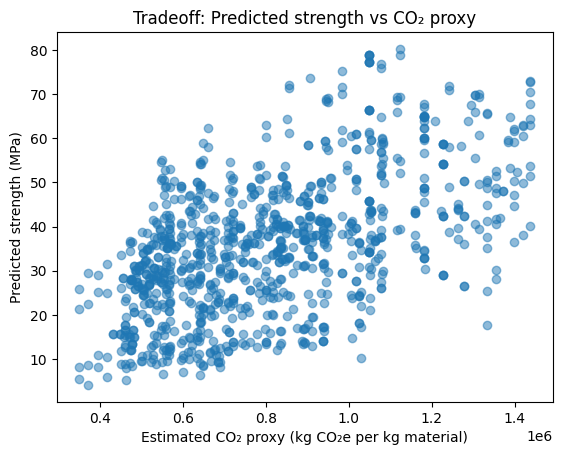

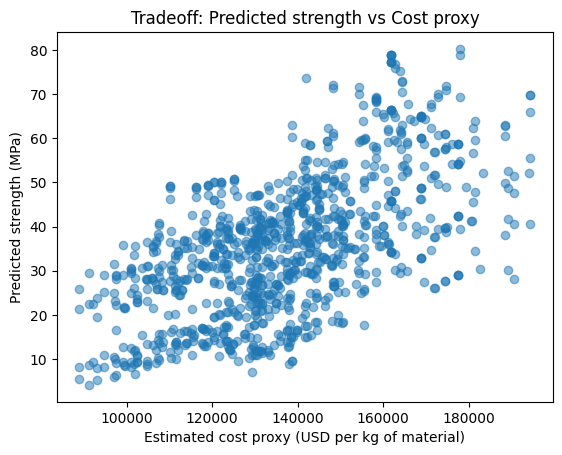

In [12]:
# Strength vs CO2 proxy
plt.figure()
plt.scatter(df_proxy["co2_proxy_kg"], df_proxy["pred_strength_mpa"], alpha=0.5)
plt.xlabel("Estimated CO₂ proxy (kg CO₂e per kg material)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Tradeoff: Predicted strength vs CO₂ proxy")
plt.show()

# Strength vs Cost proxy
plt.figure()
plt.scatter(df_proxy["cost_proxy_USD"], df_proxy["pred_strength_mpa"], alpha=0.5)
plt.xlabel("Estimated cost proxy (USD per kg of material)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Tradeoff: Predicted strength vs Cost proxy")
plt.show()


**Tradeoff Scatterplots (Proxy Analysis):** Although a positive relationship exists between increasing cost/CO₂ and increasing concrete compressive strength, it is clear that a non-linear relationship exists between cost/CO₂ and predicted strength. This indicates that there are many different mixtures to optimize either factor based on the chosen features.

## 9) Identify “better” mixtures (simple Pareto idea)

A mixture is **Pareto-optimal** if no other mixture is **higher strength** AND **lower emissions** at the same time. This isn’t a perfect optimization (because this dataset is observational), but it’s a clean way to show *tradeoffs*.


Pareto candidates: 24


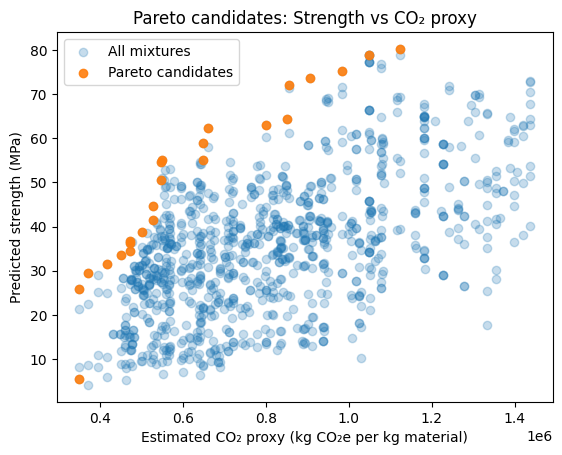

,pred_strength_mpa,co2_proxy_kg,cost_proxy_USD,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate
652,5.388833,350211.66780,88938.910,102.0,153.0,0.0,192.0,0.0,887.0,942.0
653,25.870791,350211.66780,88938.910,102.0,153.0,0.0,192.0,0.0,887.0,942.0
659,29.557537,370732.34264,91189.316,108.3,162.4,0.0,203.5,0.0,938.2,849.0
650,31.505015,416633.78854,97099.011,122.6,183.9,0.0,203.5,0.0,958.2,800.1
683,33.594237,449837.81400,101802.972,133.0,200.0,0.0,192.0,0.0,927.4,839.2
16,34.494402,472853.93684,106941.170,139.6,209.4,0.0,192.0,0.0,1047.0,806.9
23,36.303448,472853.93684,106941.170,139.6,209.4,0.0,192.0,0.0,1047.0,806.9
66,36.696405,472853.93684,106941.170,139.6,209.4,0.0,192.0,0.0,1047.0,806.9
458,38.695684,501855.10880,121512.840,165.0,0.0,143.6,163.8,0.0,1005.6,900.9
297,41.467968,526555.01672,133405.672,168.9,42.2,124.3,158.3,10.8,1080.8,796.2


In [13]:
# Simple Pareto front for max strength and minimum CO₂
points = df_proxy[["pred_strength_mpa", "co2_proxy_kg"]].to_numpy()

# Sort by ascending CO₂ values, then keep points with maximum strength
order = np.argsort(points[:, 1])
sorted_pts = points[order]

# Stores and tracks best scores
pareto_idx = []
best_strength = -np.inf
# Loops through sorted_pts and updates best strength found
# Final check before selecting points
for i, (s, c) in enumerate(sorted_pts):
    if s > best_strength:
        best_strength = s
        pareto_idx.append(order[i])

# Selects optimal points and sorts by CO₂
df_pareto = df_proxy.iloc[pareto_idx].sort_values("co2_proxy_kg")
print("Pareto candidates:", df_pareto.shape[0])

# Plots and graphs results
plt.figure()
plt.scatter(df_proxy["co2_proxy_kg"], df_proxy["pred_strength_mpa"], alpha=0.25, label="All mixtures")
plt.scatter(df_pareto["co2_proxy_kg"], df_pareto["pred_strength_mpa"], alpha=0.9, label="Pareto candidates")
plt.xlabel("Estimated CO₂ proxy (kg CO₂e per kg material)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Pareto candidates: Strength vs CO₂ proxy")
plt.legend()
plt.show()

# Forms a table of Pareto candidates for publication
df_pareto[[
    "pred_strength_mpa", "co2_proxy_kg", "cost_proxy_USD"
] + [c for c in FEATURE_MAP.keys() if c in df_pareto.columns]].head(15)


In [16]:
# Saves Pareto candidate table to folder
pareto_table_path = OUT_DIR / f"pareto_candidates_{OUTPUT_PREFIX}.csv"
df_pareto.to_csv(pareto_table_path, index=False)

print("Saved Pareto candidate table to:", pareto_table_path)

# Saves Pareto candidate graph to folder
pareto_fig_path = FIG_DIR / f"pareto_candidates_{OUTPUT_PREFIX}.png"
plt.savefig(pareto_fig_path, dpi=300, bbox_inches="tight")

print("Saved Pareto plot to:", pareto_fig_path)

Saved Pareto candidate table to: /content/drive/MyDrive/Indigo Research Project/outputs/pareto_candidates_baseline.csv
Saved Pareto plot to: /content/drive/MyDrive/Indigo Research Project/figures/pareto_candidates_baseline.png


<Figure size 640x480 with 0 Axes>

**Pareto Candidates Scatterplot (Proxy Analysis):** The graph demonstrates there is an upper limit to the amount of concrete compressive strength a mixture can contain as CO₂ increases. However, mixtures generally need to output higher levels of CO₂ before increasing in strength, matching previous graphs that highlighted cement as an important feature, for example (notice how the level of cement increases as predicted strength increases).

# Eco-Concrete Strength Modeling (Notebook 2)
## Cross-Validation, Tuning, and Publication-Ready Outputs

**Goal:** Make your modeling results **more defensible** by adding cross-validation, basic hyperparameter tuning, and exportable figures/tables for the paper + GitHub

### What this notebook adds:
1. Robust data loading (Local or Colab + Google Drive)
2. Cross-validation evaluation (R², MAE)
3. Simple hyperparameter tuning (Random Forest + Gradient Boosting)
4. “Holdout test” evaluation on an untouched test set
5. Publication-ready outputs:
   - figures saved to `./figures/`
   - results tables saved to `./outputs/`
6. A sustainability proxy section

---
## Expected folder structure example (recommended)
If running locally or in a Drive-synced folder:
```
Research Project/
  notebooks/
    02_eco_concrete_cv_tuning_outputs.ipynb
  data/
    Concrete_Data.csv
  figures/
  outputs/
  src/
```


## 1) Data loading options (Local vs Colab)

### Option A: relative `data/` folder (local or Drive-synced)
Keep your CSV here:
```
./data/Concrete_Data.csv
```

### Option B: Colab + Google Drive
Mount Drive, then set `BASE_DIR` to your Drive path (example below).

> Tip: In Colab, Drive paths look like `/content/drive/MyDrive/...`

Refer to the top of the notebook for data loading.


## 2) Clean column names + identify the target

We normalize column names and auto-detect the compressive strength target column.


In [19]:
# Normalizes column names
def normalize_col(c: str) -> str:
    c = c.strip().lower()
    c = c.replace(" ", "_").replace("-", "_")
    c = c.replace("(", "").replace(")", "")
    while "__" in c:
        c = c.replace("__", "_")
    return c

# Prevents original dataframe from being modified
df = df.copy()
# Continues to normalize
df.columns = [normalize_col(c) for c in df.columns]
# Searches for possible target columns (strength, compressive)
possible_targets = [c for c in df.columns if "strength" in c or "compressive" in c]
print("Possible target columns:", possible_targets)

# Looks for mpa and defines target column
TARGET_COL = None
for c in possible_targets:
    if "mpa" in c:
        TARGET_COL = c
        break
if TARGET_COL is None and len(possible_targets) == 1:
    TARGET_COL = possible_targets[0]
if TARGET_COL is None and "concrete_compressive_strength" in df.columns:
    TARGET_COL = "concrete_compressive_strength"

if TARGET_COL is None:
    raise ValueError("Could not auto-detect TARGET_COL. Please set it manually.")

print("Using TARGET_COL =", TARGET_COL)

# Checks for leftover strings, converts strings to numerics
for c in df.columns:
    if c == TARGET_COL:
        continue
    if df[c].dtype == "object":
        df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=[TARGET_COL]).reset_index(drop=True)

numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
feature_cols = [c for c in numeric_cols if c != TARGET_COL]

# x is the numeric, y is the value
X = df[feature_cols].copy()
y = df[TARGET_COL].copy()

print("Rows:", len(df))
print("Features:", feature_cols)


Possible target columns: ['concrete_compressive_strength']
Using TARGET_COL = concrete_compressive_strength
Rows: 1030
Features: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']


## 3) Train/test split (holdout test set)

All cross-validation and tuning happen only on the training set.


In [20]:
# Splits x and y into, 80% training, 20% testing (what the data is based on).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (824, 8) Test: (206, 8)


## 4) Cross-validation baseline evaluation (5-fold)

We compute mean ± STD for **R²** and **MAE** on the training set.


In [21]:
# Does baseline evaluation of the 3 models
    # Takes the mean, R^2, and mean absolute error + the standard deviation of each
def mae_scorer():
    return make_scorer(mean_absolute_error, greater_is_better=False)

# Initiates 5 fold cross-validation for machine learning
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Refer to Notebook 1 for variable explanation
models = {
    "LinearRegression": Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())]),
    "RandomForest": RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring={"r2": "r2", "mae": mae_scorer()},
        return_train_score=False
    )
    rows.append({
        "model": name,
        "cv_r2_mean": float(np.mean(scores["test_r2"])),
        "cv_r2_std": float(np.std(scores["test_r2"])),
        "cv_mae_mean": float(-np.mean(scores["test_mae"])),
        "cv_mae_std": float(np.std(-scores["test_mae"])),
    })

# Creates cross validation performance, compares the models
cv_df = pd.DataFrame(rows).sort_values("cv_r2_mean", ascending=False)
cv_df


,model,cv_r2_mean,cv_r2_std,cv_mae_mean,cv_mae_std
1,RandomForest,0.900023,0.016448,3.673030,0.240467
2,GradientBoosting,0.891328,0.017048,3.981997,0.294528
0,LinearRegression,0.597135,0.047330,8.421618,0.406350


In [22]:
# Save cross validation table to CSV
cv_path = os.path.join(OUT_DIR, "cv_summary.csv")
cv_df.to_csv(cv_path, index=False)
print("Saved:", cv_path)


Saved: /content/drive/MyDrive/Indigo Research Project/outputs/cv_summary.csv


## 5) Hyperparameter tuning (small grid search)

This is enough to justify that you tried reasonable settings without overfitting.


In [23]:
# Initializes random forest model
rf = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)

# Setting up a random forest hyperparameter grid for tuning
rf_grid = {
    # Number of trees
    "n_estimators": [300, 600],
    # Maximum depth each individual decision tree (growth limit)
    "max_depth": [None, 8, 14],
    # Minimum number of samples in final prediction of each tree
    "min_samples_leaf": [1, 2, 4],
}

# Print out best parameters and best cross-validation score
rf_search = GridSearchCV(rf, rf_grid, cv=cv, scoring="r2", n_jobs=-1)
rf_search.fit(X_train, y_train)

# Prints results
print("Best RF params:", rf_search.best_params_)
print("Best RF CV R²:", rf_search.best_score_)


Best RF params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
Best RF CV R²: 0.9001438482877994


In [24]:
from sklearn.ensemble import GradientBoostingRegressor

# Initializes gradient boosting regressor
gbr = GradientBoostingRegressor(random_state=RANDOM_STATE)

# Same processes as previous cell
gbr_grid = {
    # Number of boosting stages or sequential decision trees
    "n_estimators": [200, 400],
    # Shrinkage factor, contribution of each individual tree
    "learning_rate": [0.03, 0.07, 0.1],
    # Maximum depth of each individual regression tree
    # Controls complexity of each learner
    "max_depth": [2, 3],
}

# Print out best parameters and best cross-validation score
gbr_search = GridSearchCV(gbr, gbr_grid, cv=cv, scoring="r2", n_jobs=-1)
gbr_search.fit(X_train, y_train)

# Prints results
print("Best GBR params:", gbr_search.best_params_)
print("Best GBR CV R²:", gbr_search.best_score_)

Best GBR params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400}
Best GBR CV R²: 0.9155329529072549


## 6) Final test-set evaluation

We evaluate the tuned models on the holdout test set and save a results table.


In [25]:
# Using models on untouched test set, compares the training set to the test set
def eval_on_test(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    return {
        "model": name,
        "test_r2": float(r2_score(y_test, pred)),
        "test_mae": float(mean_absolute_error(y_test, pred)),
        "pred": pred,
        "fitted": model
    }

# Defines final_models
final_models = {
    "LinearRegression": Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())]),
    "RandomForest_tuned": rf_search.best_estimator_,
    "GradientBoosting_tuned": gbr_search.best_estimator_,
}

# Creating a CSV and saving best R^2 based on the 3 models (ranked)
final_rows = []
final_store = {}
for name, m in final_models.items():
    out = eval_on_test(name, m)
    final_rows.append({k: out[k] for k in ["model", "test_r2", "test_mae"]})
    final_store[name] = out

final_df = pd.DataFrame(final_rows).sort_values("test_r2", ascending=False)
final_df


,model,test_r2,test_mae
2,GradientBoosting_tuned,0.919526,3.121004
1,RandomForest_tuned,0.880857,3.788964
0,LinearRegression,0.627553,7.745559


In [26]:
# Saves CSV to outputs
final_path = os.path.join(OUT_DIR, "test_set_results.csv")
final_df.to_csv(final_path, index=False)
print("Saved:", final_path)


Saved: /content/drive/MyDrive/Indigo Research Project/outputs/test_set_results.csv


## 7) Save publication-ready figures

Predicted vs Actual and Feature Importance plots saved into `figures/`.


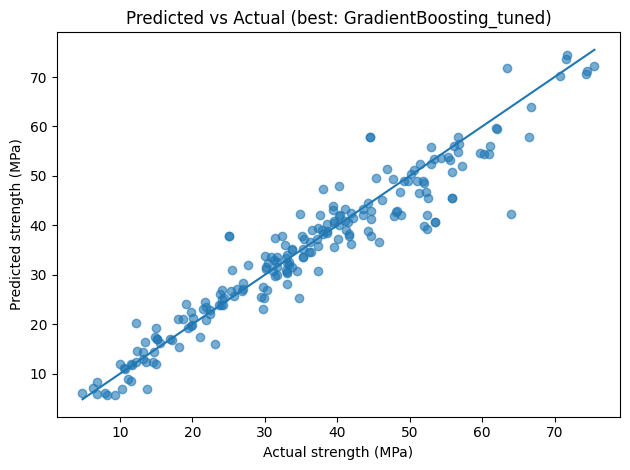

Saved: /content/drive/MyDrive/Indigo Research Project/figures/pred_vs_actual_GradientBoosting_tuned.png


In [27]:
# Saves figures (best models) to figures directory
best_name = final_df.iloc[0]["model"]
best = final_store[best_name]
best_model = best["fitted"]
y_pred = best["pred"]

# Creates a scatterplot comparing predicted v actual compressive strength
plt.figure()
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title(f"Predicted vs Actual (best: {best_name})")

mn = min(y_test.min(), y_pred.min())
mx = max(y_test.max(), y_pred.max())
plt.plot([mn, mx], [mn, mx])
plt.tight_layout()

# Saves figure and prints
fig_path = os.path.join(FIG_DIR, f"pred_vs_actual_{best_name}.png")
plt.savefig(fig_path, dpi=200)
plt.show()
print("Saved:", fig_path)


**Predicted vs Actual Scatterplot:** The Gradient Boosting model seems to cluster around the plotted line, indicating reasonable model prediction accuracy with few outliers.

Saved: /content/drive/MyDrive/Indigo Research Project/outputs/permutation_importance_GradientBoosting_tuned.csv


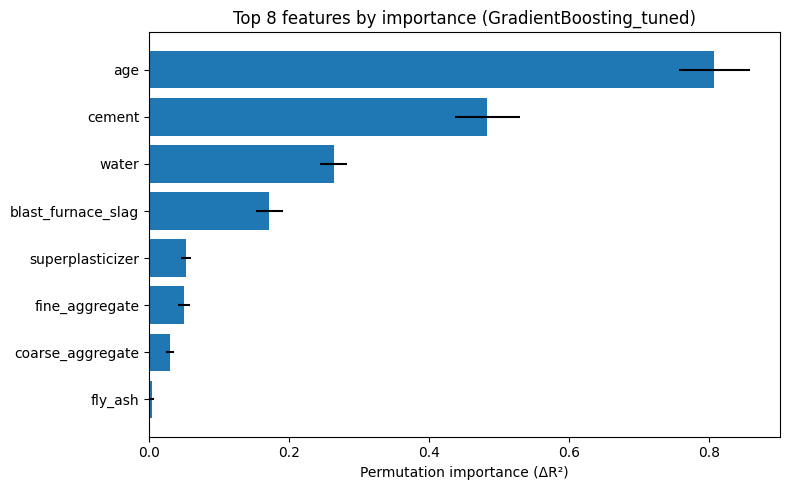

Saved: /content/drive/MyDrive/Indigo Research Project/figures/feature_importance_GradientBoosting_tuned.png


,feature,importance_mean,importance_std
7,age,0.806979,0.050836
0,cement,0.482777,0.046296
3,water,0.263746,0.019052
1,blast_furnace_slag,0.171511,0.019116
4,superplasticizer,0.052413,0.007017
6,fine_aggregate,0.049701,0.008414
5,coarse_aggregate,0.030050,0.005563
2,fly_ash,0.004214,0.002632


In [28]:
# For the best model, what is the best features of the model?
perm = permutation_importance(
    best_model, X_test, y_test,
    # Ensures results are accurate, computationally expensive as n_repeats increases
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="r2"
)

# Plots the importance of each feature found in previous code ^
imp = pd.DataFrame({
    "feature": feature_cols,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

# Saves permutation importance graph to a CSV file
imp_path = os.path.join(OUT_DIR, f"permutation_importance_{best_name}.csv")
imp.to_csv(imp_path, index=False)
print("Saved:", imp_path)

# Number of variables considered
top_k = min(12, len(feature_cols))
# Takes variables and reverses the horizontal bar order
top = imp.head(top_k).iloc[::-1]

# Plots and saves tabled data on feature importance
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Permutation importance (ΔR²)")
plt.title(f"Top {top_k} features by importance ({best_name})")
plt.tight_layout()

imp_fig = os.path.join(FIG_DIR, f"feature_importance_{best_name}.png")
plt.savefig(imp_fig, dpi=200)
plt.show()
print("Saved:", imp_fig)

imp.head(12)


**Feature Importance Bar Graph:** Age, cement, and water seem to be the most important features when considering concrete compressive strength, as in they have the greatest effect. This graph matches real-world observations but does not show the relationship between the feature and the compressive strength of a mixture. Thus, graphs such as the correlation heatmap can be used alongside feature importance to better understand these variables.

## 8) Sustainability layer (CO₂ + cost proxies)

**Important:** The current dataset does *not* include CO₂ emissions or cost.  
To determine sustainability, we create *proxies* from mixture composition.

### How to use this section responsibly
- Treat these as **scenario estimates**, not ground-truth lifecycle assessments.
- Use **literature/CSI** sources to justify the factors you pick.
- Label all plots as proxy analysis unless all values are supported by literature/CSI sources

### Simple proxy approach
Estimate emissions as:
- `CO2_kg = sum_i (mass_i_kg_per_m3 * factor_i_kgCO2_per_kg)`
- `USD_kg = sum_i (mass_i_kg_per_m3 * factor_i_kgUSD_per_kg)`

The current values are defined by literature results and market value estimations as of June 2026.

In [29]:
# Note
    # Current values should be defined or replaced by relevant literature results
    # Current calculations uses GGBFS and natural aggregate data
# CO2 measured in kg CO₂e per kg of material
# Formula determined by material amount in kg/m³ multiplied by factor in kg CO₂e/kg
CO2_FACTORS = {
    "cement": 2614.5,
    "blast_furnace_slag": 393.6586,
    "fly_ash": 314.65,
    "water": 0.196,
    "superplasticizer": 300,
    "coarse_aggregate": 19.05,
    "fine_aggregate": 6.76,
}

# Cost measured in USD per kg of material
# Formula determined by material amount in kg/m³ multiplied by factor in USD/kg
COST_FACTORS = {
    "cement": 226.80,
    "blast_furnace_slag": 148.65,
    "fly_ash": 273.42,
    "water": 9.60,
    "superplasticizer": 963.84,
    "coarse_aggregate": 24.38,
    "fine_aggregate": 20.80,
}

FEATURE_MAP = {
    "cement": "cement",
    "blast_furnace_slag": "blast_furnace_slag",
    "fly_ash": "fly_ash",
    "water": "water",
    "superplasticizer": "superplasticizer",
    "coarse_aggregate": "coarse_aggregate",
    "fine_aggregate": "fine_aggregate",
}

# Computes trade off between CO2/cost and compressive strength
def compute_proxy(df_in: pd.DataFrame, factors: dict, feature_map: dict) -> pd.Series:
    total = np.zeros(len(df_in), dtype=float)
    for col, key in feature_map.items():
        if col in df_in.columns and key in factors:
            total += df_in[col].values * float(factors[key])
    return pd.Series(total, index=df_in.index)

df_proxy = df.copy()
df_proxy["co2_proxy_kg"] = compute_proxy(df_proxy, CO2_FACTORS, FEATURE_MAP)
df_proxy["cost_proxy_USD"] = compute_proxy(df_proxy, COST_FACTORS, FEATURE_MAP)
df_proxy["pred_strength_mpa"] = best_model.predict(df_proxy[feature_cols])

df_proxy[["pred_strength_mpa", "co2_proxy_kg", "cost_proxy_USD"]].describe().T


,count,mean,std,min,25%,50%,75%,max
pred_strength_mpa,1030.0,35.676538,16.320589,2.513019,24.137611,35.163618,44.558347,8.153978e+01
co2_proxy_kg,1030.0,806913.966899,257342.614450,350211.667800,593878.622000,774754.220350,983831.048800,1.437439e+06
cost_proxy_USD,1030.0,137103.247764,21940.533638,88938.910000,122040.221000,136063.306000,150546.604500,1.944061e+05


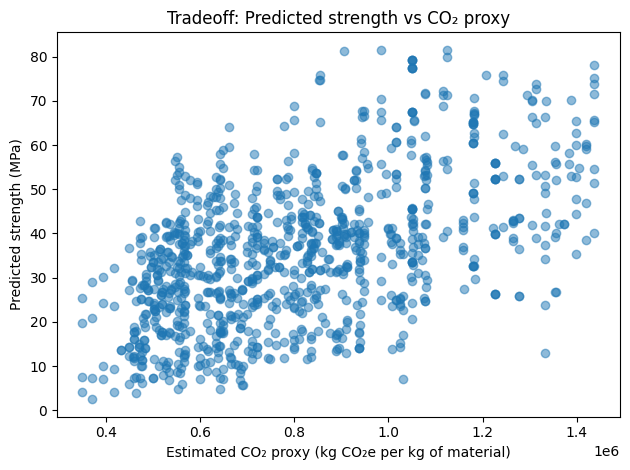

Saved: /content/drive/MyDrive/Indigo Research Project/figures/tradeoff_strength_vs_co2_proxy.png


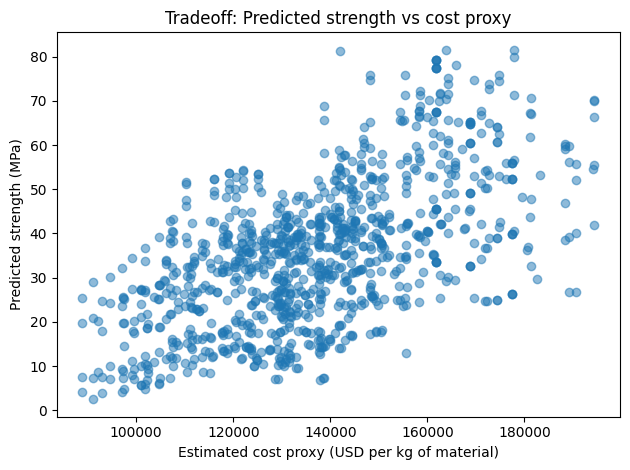

Saved: /content/drive/MyDrive/Indigo Research Project/figures/tradeoff_strength_vs_cost_proxy.png


In [30]:
# Plots results of previous cell
plt.figure()
plt.scatter(df_proxy["co2_proxy_kg"], df_proxy["pred_strength_mpa"], alpha=0.5)
plt.xlabel("Estimated CO₂ proxy (kg CO₂e per kg of material)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Tradeoff: Predicted strength vs CO₂ proxy")
plt.tight_layout()
t1 = os.path.join(FIG_DIR, "tradeoff_strength_vs_co2_proxy.png")
plt.savefig(t1, dpi=200)
plt.show()
print("Saved:", t1)

plt.figure()
plt.scatter(df_proxy["cost_proxy_USD"], df_proxy["pred_strength_mpa"], alpha=0.5)
plt.xlabel("Estimated cost proxy (USD per kg of material)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Tradeoff: Predicted strength vs cost proxy")
plt.tight_layout()
t2 = os.path.join(FIG_DIR, "tradeoff_strength_vs_cost_proxy.png")
plt.savefig(t2, dpi=200)
plt.show()
print("Saved:", t2)


**Tradeoff Scatterplots (Proxy Analysis):** Although a positive relationship exists between increasing cost/CO₂ and increasing concrete compressive strength, it is clear that a non-linear relationship exists between cost/CO₂ and predicted strength. This indicates that there are many different mixtures to optimize either factor based on the chosen features.

## 9) Method Overview

**Dataset:** Concrete Compressive Strength dataset (Kaggle) with mixture composition features (kg/m³) and curing age (days).  
**Target:** compressive strength (MPa).  
**Models:** linear regression baseline, random forest, and gradient boosting.  
**Evaluation:** 5-fold cross-validation on the training set and final performance on a held-out test set using R² and mean absolute error (MAE).  
**Tuning:** small grid search over key hyperparameters for tree-based models.  
**Interpretation:** permutation importance computed on the test set for the best-performing model.  

Label any CO₂ and cost quantities as **proxy estimates** unless replaced by cited lifecycle data.
